# What a network sees of a hologram

**Question:** What goes into the released network and what comes out, for one three-plane target, and what is the score the network is held to?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 01-fourier-optics (the focal field and the trap metrics)
- **Reading time:** about 35 minutes; the notebook runs in about 15 seconds

## Objectives

A learned hologram is a file: a neural network saved as an ONNX graph that takes an image and returns a phase mask. Before asking whether it is good, a reader has to know exactly what the graph is given, what it returns and how its output is turned back into light. This notebook walks one target through the product's released network, `cgh-net`: twelve traps on three depths. You will read what the card of the graph promises, build the network's input from the traps, run the graph through onnxruntime, rebuild by hand the images the phase makes at each depth and the accuracy the network is scored by, and put that number next to two holograms that know nothing about the target. At the end you will be able to say what a number like 0.73 means and what it does not.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.31.1
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The network is the product's released ONNX graph, the same file the browser runs, read through onnxruntime. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import json
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, modes
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.learned import convert, evaluation
from pipeline.model.holo.methods.learned import m17_cgh_net

for name in ("numpy", "matplotlib", "onnxruntime"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.31.1


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic. The case is written by the product and the network was trained on targets drawn from a seeded generator, so no third-party dataset applies and the repository licence covers every file.
- Files read: `data/examples/cases.json` (case C05, the optics at 1064 nm and the lattice of sites), the released graph `models/cgh-net.onnx` and its card `models/cgh-net.json`.

Case C05 was written for a 256 by 256 pixel SLM, and the network was trained for 128 by 128 pixels with no padding. The next cell keeps the optics of the case (1064 nm, a 2.4 mm focal length, 10 um pixels) and sets the grid to the network's, then prints what the card says the graph takes and returns.

In [2]:
# case C05 gives the optics and the lattice; the card of the released graph says what the network was built for
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C05_multiplane_vortices"]
setup = replace(setup_of(rec), n_pix=128, pad=1)
card = json.loads((ROOT / "models" / "cgh-net.json").read_text(encoding="utf-8"))
bin_m, zr = focal_bin_m(setup), convert.rayleigh_range_m(setup)
print(f"card: slot {card['slot']}, opset {card['opset']}, {card['bytes'] / 1e6:.2f} MB, grid {card['grid']}")
port_in, port_out = card["inputs"][0], card["outputs"][0]
print(f"card input: {port_in['name']} {port_in['shape']}")
print(f"card output: {port_out['name']} {port_out['shape']}")
print(f"one focal bin = {bin_m * 1e6:.3f} um, one Rayleigh range of the aperture = {zr * 1e6:.2f} um")

card: slot cgh-net, opset 17, 4.67 MB, grid 128
card input: target [1, 3, 128, 128]
card output: phase [1, 1, 128, 128]
one focal bin = 1.995 um, one Rayleigh range of the aperture = 4.76 um


The card states the contract. The graph takes one array of shape 1 by 3 by 128 by 128, three images of 128 by 128 bins, and returns one array of shape 1 by 1 by 128 by 128, a phase for a 128 by 128 SLM. A focal bin is 1.995 um on this optics, and the unit of depth is the Rayleigh range of the SLM aperture, 4.76 um.

## Method

**The target.** The network was built after DeepCGH (Eybposh et al. 2020, https://doi.org/10.1364/OE.399624): a convolutional network maps the intensity wanted at several planes to one phase for the SLM. In the product's version, M17, the planes are at $z = -8$, $0$ and $+8$ Rayleigh ranges $z_R = \lambda f^2 / (\pi R^2)$ of the aperture of radius $R = N p/2$, the traps sit on whole focal bins within 60 bins of the axis, the targets it was trained on have the same number of traps on every plane, and none carries a vortex charge. Each trap is drawn as a Gaussian spot one bin wide, and each plane's image is scaled to unit energy.

**The score.** With $T_p$ the target image of plane $p$ and $I_p$ the intensity the hologram makes there, both scaled to unit sum, the accuracy is $AC = \frac{1}{3}\sum_p 2\sum T_p I_p / (\sum T_p^2 + \sum I_p^2)$. It is 1 when the two images are identical and falls toward 0 as they stop overlapping. The product uses this reading of the DeepCGH measure for the training loss, the baselines and the evaluation alike; the paper's own formula was not opened for this notebook, so that match is UNVERIFIED. The plane image of a phase $\phi$ is $I_p = |\mathcal{F}\{A\,e^{i(\phi - \phi_{z_p})}\}|^2$, where $\phi_{z_p}$ is the lens term that focuses the SLM at depth $z_p$.

The first step builds the target. The cell takes twelve sites of the case's lattice and puts each on one depth only, four on each of the three planes, so that the planes differ and no site is repeated.

In [3]:
# twelve sites of the C05 lattice, each on one depth only: four per plane at -8, 0 and +8 ranges
sites = [t for t in rec["target"]["traps"] if t["charge"] == 0 and t["z_um"] == 0.0][:12]
placed = []
for k, t in enumerate(sites):
    x_bin, y_bin = round(t["x_um"] * 1e-6 / bin_m), round(t["y_um"] * 1e-6 / bin_m)
    placed.append(Trap(k, x_bin * bin_m, y_bin * bin_m, (k % 3 - 1) * 8 * zr))
target = Target.from_traps(TrapSet(placed))
depth = np.rint(target.traps.z_m / (8 * zr)).astype(int)
print("traps per plane (-8, 0, +8 ranges):", np.bincount(depth + 1).tolist())
print("lateral positions (bins):", [(round(t.x_m / bin_m), round(t.y_m / bin_m)) for t in placed[:3]], "...")

traps per plane (-8, 0, +8 ranges): [4, 4, 4]
lateral positions (bins): [(4, 0), (2, 3), (-4, 0)] ...


Four traps per plane, as the network expects. The next step turns them into its input with the product's own function; the input should be mostly zeros with twelve small bright spots.

In [4]:
# the network's input: one amplitude image per plane, each with unit energy
amps = m17_cgh_net.planes_from_traps(setup, target.traps)
print("input array:", amps.shape, amps.dtype)
print("energy per plane:", (amps.astype(float) ** 2).sum(axis=(2, 3)).round(3).tolist()[0])
lit = int((amps > 0.01 * amps.max()).sum())
print(f"largest amplitude {amps.max():.4f}, bins above 1 % of it: {lit} of {amps.size}")

input array: (1, 3, 128, 128) float32
energy per plane: [1.0, 1.0, 1.0]
largest amplitude 0.1995, bins above 1 % of it: 577 of 49152


It is: one array of 1 by 3 by 128 by 128 numbers of type float32, each plane with energy 1.0, and only 577 of the 49152 values above one percent of the largest amplitude, 0.1995. That is what the network sees: no phases, no hologram, only where the light should be and at which depth. The figure draws the squared amplitude, the intensity the network is asked for, in a window of 80 by 80 bins around the axis at each of the three depths.

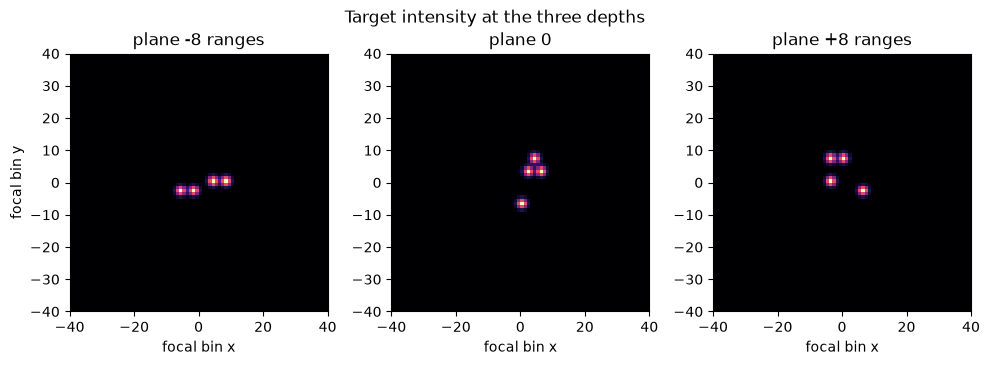

In [5]:
# the three planes of the target as the intensity the network is asked for
DEPTHS = ("plane -8 ranges", "plane 0", "plane +8 ranges")
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, image, name in zip(axes, amps[0], DEPTHS):
    ax.imshow(image[24:104, 24:104] ** 2, cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    ax.set_title(name)
    ax.set_xlabel("focal bin x")
axes[0].set_ylabel("focal bin y")
fig.suptitle("Target intensity at the three depths")
fig.tight_layout()
plt.show()

Each panel holds four spots about two bins across, and no two panels share a position, so the three planes are different patterns. What the network is given is therefore a stack of three pictures, not a list of coordinates: it has no notion of a trap, only of bright pixels. The figure does not show the depth as a number, because the depth is the position of the picture in the stack, first, second or third. A different depth than the three of training would have no way of being asked, which is why the product's method refuses targets that are not on these three planes. The next step gives the graph this input.

The second step runs the graph. The cell opens the ONNX file with onnxruntime on the CPU, prints the name, shape and type of each port that the file itself declares, and calls the product's `predict` on the input. As a check on the way the product wraps the file, it also calls the full method with its refinement switched off, and compares the phase.

In [6]:
# the released graph through onnxruntime: what the session declares, and the phase it returns for this input
session = ort.InferenceSession(str(ROOT / "models" / "cgh-net.onnx"), providers=["CPUExecutionProvider"])
for port in session.get_inputs() + session.get_outputs():
    print(port.name, port.shape, port.type)
phase = m17_cgh_net.predict(session, amps)
print("phase mask:", phase.shape, phase.dtype, f"range {phase.min():.3f} to {phase.max():.3f} rad")
whole = m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)
print("the method with the refinement off returns the same phase:", bool(np.allclose(whole.phi, phase, atol=1e-5)))

target [1, 3, 128, 128] tensor(float)
phase [1, 1, 128, 128] tensor(float)
phase mask: (128, 128) float64 range -3.141 to 3.141 rad
the method with the refinement off returns the same phase: True


The file declares the same two ports as the card, the input `target` and the output `phase`, and the phase is a 128 by 128 array that runs from -3.141 to 3.141 rad, so it is wrapped to one turn. The full method with the refinement off returns the same phase, so a pass of the graph is the whole of what `cgh-net` does in this mode. The phase is one mask for all three planes: the network has to find a single pattern that, focused at three different depths, makes three different pictures.

The third step rebuilds the score by hand. The cell defines the image of a phase at one depth, refocusing with the engine's lens term and taking the focal FFT of the engine, scales the target images to unit sum and applies the formula of the Method section to each plane. It prints the three values and their mean next to the product's own `plane_accuracy`.

In [7]:
# the hologram at each depth: refocus with the plane's lens term, focal FFT, unit sum
images = []
for ranges in (-8, 0, 8):
    field = forward.fft_focal_field(phase - modes.lens_phase(setup, ranges * zr), setup)
    intensity = np.abs(field) ** 2
    images.append(intensity / intensity.sum())
wanted = [(a.astype(float) ** 2) / np.sum(a.astype(float) ** 2) for a in amps[0]]
by_hand = [2 * np.sum(w * i) / (np.sum(w**2) + np.sum(i**2)) for w, i in zip(wanted, images)]
print("accuracy per plane by hand:", np.round(by_hand, 4).tolist(), "mean", round(float(np.mean(by_hand)), 4))
print("the product's own function:", round(evaluation.plane_accuracy(amps[0], phase, setup), 4))

accuracy per plane by hand: [0.8276, 0.5724, 0.7859] mean 0.7286
the product's own function: 0.7286


The accuracy is 0.8276 on the plane at -8, 0.5724 on the middle plane and 0.7859 on the plane at +8, and their mean, 0.7286, is the number the product's function returns, so the by-hand definition is the product's. The middle plane is the weakest by a wide margin. This notebook has one target and one network, so it cannot say whether the middle plane is systematically harder or whether the four spots of this plane are an awkward set; it only reports what is measured.

The fourth step gives the number a scale. A score of 0.73 means little until it sits beside holograms that did not look at the target. The cell scores the network, an unmodulated SLM (a flat phase) and a random phase, with the same function, and then the score of a plane identical to its target, which is the ceiling of the scale.

In [8]:
# three holograms through the same scorer: the network, an unmodulated SLM and a random phase
random_phase = np.random.default_rng(7).uniform(-np.pi, np.pi, phase.shape)
candidates = {"cgh-net": phase, "flat phase": np.zeros_like(phase), "random phase": random_phase}
scores = {name: evaluation.plane_accuracy(amps[0], phi, setup) for name, phi in candidates.items()}
for name, value in scores.items():
    print(f"{name:12s} accuracy {value:.4f}  loss {1 - value:.4f}")
perfect = np.mean([2 * np.sum(w * w) / (np.sum(w**2) + np.sum(w**2)) for w in wanted])
print(f"a plane identical to its target scores {perfect:.4f}")

cgh-net      accuracy 0.7286  loss 0.2714
flat phase   accuracy 0.1196  loss 0.8804
random phase accuracy 0.0068  loss 0.9932
a plane identical to its target scores 1.0000


The network scores 0.7286, the flat phase 0.1196 and the random phase 0.0068, and a plane identical to the target scores 1.0000. The loss, one minus the accuracy, is 0.2714, 0.8804 and 0.9932. A random phase scatters the light into speckle and leaves almost nothing on the target, and a flat phase makes the same pattern whatever the target is. The figure shows the network's mask on the left and, in the three panels to its right, the intensity that mask makes at each depth with the twelve target sites circled in cyan, on a square-root scale so that the light between the spots is visible.

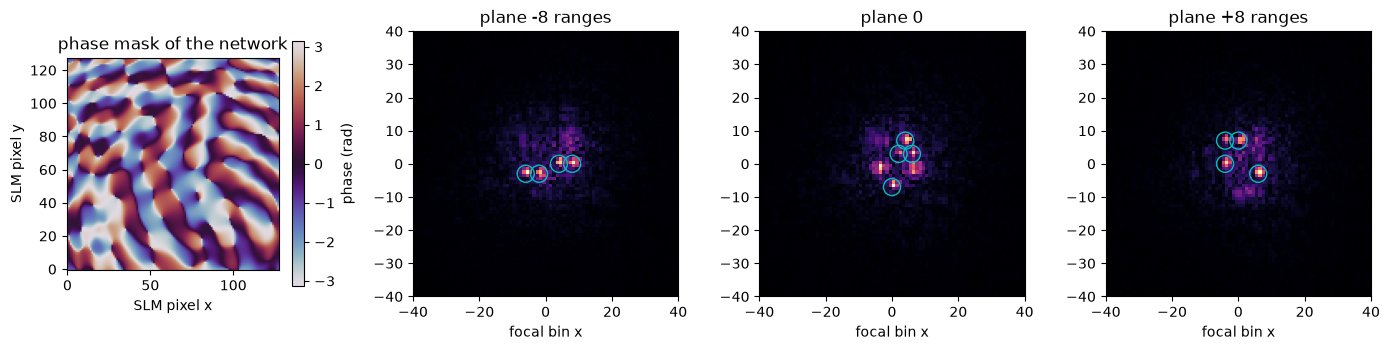

In [9]:
# the phase mask and the intensity it makes at the three depths, target sites circled
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
mask = axes[0].imshow(phase, cmap="twilight", vmin=-np.pi, vmax=np.pi, origin="lower")
axes[0].set_title("phase mask of the network")
axes[0].set_xlabel("SLM pixel x")
axes[0].set_ylabel("SLM pixel y")
fig.colorbar(mask, ax=axes[0], label="phase (rad)", shrink=0.8)
for ax, ranges, image, name in zip(axes[1:], (-8, 0, 8), images, DEPTHS):
    ax.imshow(np.sqrt(image[24:104, 24:104]), cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    here = target.traps.z_m == ranges * zr
    ax.scatter(target.traps.x_m[here] / bin_m, target.traps.y_m[here] / bin_m, s=150, facecolors="none", edgecolors="c")
    ax.set_title(name)
    ax.set_xlabel("focal bin x")
fig.tight_layout()
plt.show()

The mask is a smooth, swirling pattern with a fringe-like texture and no resemblance to any of the three pictures, which is how a phase hologram looks: the information is in the Fourier relationship, not in the mask's appearance. In each depth the bright points fall inside or next to the cyan circles, and each plane also carries a diffuse haze of speckle, some of it presumably the light made for the other two depths, out of focus; the figure cannot separate the two. Haze costs accuracy, because the score counts every bin and the target is almost empty. The figure does not show the intensity of each trap against the others, so it cannot tell whether the twelve spots are equal; the accuracy cannot tell either.

The last figure puts the four scores side by side as bars, the three holograms and the ceiling of the scale.

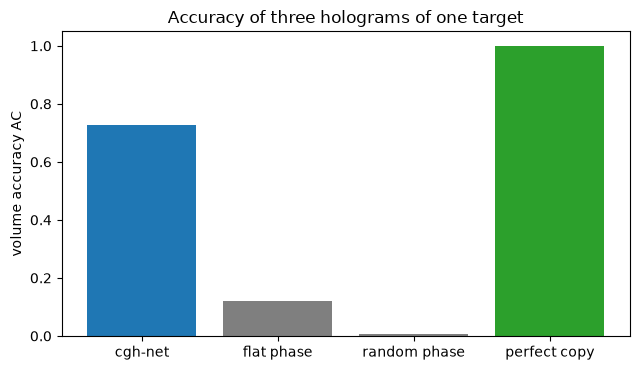

In [10]:
# the accuracy of the three holograms and of a perfect copy of the target, as bars
fig, ax = plt.subplots(figsize=(6.5, 3.8))
names = list(scores) + ["perfect copy"]
ax.bar(names, list(scores.values()) + [perfect], color=["C0", "C7", "C7", "C2"])
ax.set_ylabel("volume accuracy AC")
ax.set_title("Accuracy of three holograms of one target")
fig.tight_layout()
plt.show()

The network's bar is about seven tenths of the way from the flat phase to the perfect copy, and the flat and random bars are barely visible: an informed hologram and an uninformed one are far apart on this scale, so the metric separates them well. It does not measure how close the network is to the best phase mask that exists, because no one knows that mask, and a score of 0.73 is neither good nor bad by itself. Whether it is good is a comparison with the classical loop at the same cost, and that is the work of the later notebooks of this topic.

## Results

**Answer:** The network takes a stack of three unit-energy amplitude images, one per depth at -8, 0 and +8 Rayleigh ranges, 128 by 128 bins each, 1 by 3 by 128 by 128 float32 numbers in which only 577 of 49152 values are above one percent of the peak, and returns one 128 by 128 phase wrapped to -3.141 to 3.141 rad. It is scored by the accuracy, the mean over the three planes of a normalised overlap of the target and the intensity the phase makes there: 0.8276, 0.5724 and 0.7859 on the planes of this twelve-trap target, 0.7286 on average, which the product's own function reproduces. On the same scale a flat phase scores 0.1196, a random phase 0.0068 and a perfect copy 1.0000. The notebook shows one target and one network, so it does not say how the score varies across targets, whether the traps come out equal, or whether the classical loop does better at the same cost.

## Summary

`cgh-net` is a function from three pictures to one phase mask, with the depth carried by the order of the pictures and the target fixed to three planes, whole bins and equal counts. Its score, the accuracy, compares whole images and not the traps, and puts a flat phase at 0.1196 and the network at 0.7286 on this target. The next notebook asks how a network can learn such a function without ever being shown a correct hologram.

## References

- Eybposh, Caira, Atisa, Chakravarthula and Pégard, "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- onnxruntime 1.31.1 (MIT), https://pypi.org/pypi/onnxruntime/json and https://pypi.org/project/onnxruntime/.